In [1]:
import torch # Building GPT-2

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [3]:
from transformers import GPT2LMHeadModel

In [4]:
model_hf = GPT2LMHeadModel.from_pretrained("gpt2") # 124M
sd_hf = model_hf.state_dict()

for k, v in sd_hf.items():
    print(k, v.shape)

transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

In [5]:
sd_hf["transformer.wpe.weight"].view(-1)[:20]

tensor([-0.0188, -0.1974,  0.0040,  0.0113,  0.0638, -0.1050,  0.0369, -0.1680,
        -0.0491, -0.0565, -0.0025,  0.0135, -0.0042,  0.0151,  0.0166, -0.1381,
        -0.0063, -0.0461,  0.0267, -0.2042])

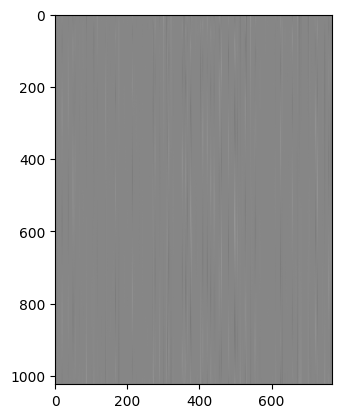

In [6]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.imshow(sd_hf["transformer.wpe.weight"], cmap='gray')

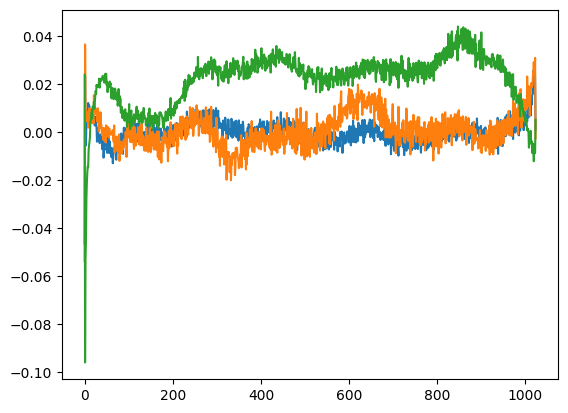

In [7]:
plt.plot(sd_hf["transformer.wpe.weight"][:, 150])
plt.plot(sd_hf["transformer.wpe.weight"][:, 200])
plt.plot(sd_hf["transformer.wpe.weight"][:, 250])


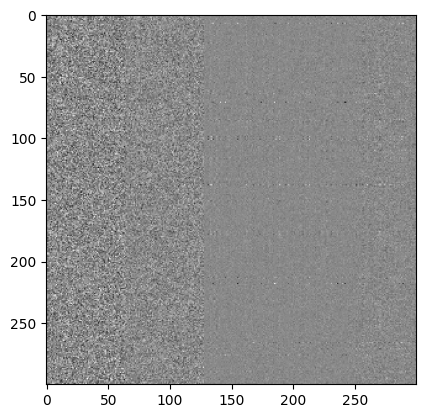

In [8]:
plt.imshow(sd_hf["transformer.h.1.attn.c_attn.weight"][:300, :300], cmap='gray')

In [9]:
print(sd_hf["lm_head.weight"].shape)
print(sd_hf["transformer.wte.weight"].shape)

torch.Size([50257, 768])
torch.Size([50257, 768])


In [10]:
print(sd_hf["lm_head.weight"].data_ptr())
print(sd_hf["transformer.wte.weight"].data_ptr())

23043569602515
23043569602515


In [13]:
# standard deviation grows inside the residual stream
x = torch.zeros(768)
n = 100
for i in range(n):
    x += n**-0.5 * torch.randn(768)
    print(i, '=', torch.randn(768))

print(x.std())

0 = tensor([-1.6838,  0.5007, -1.5050, -0.4953,  0.1161, -0.6643, -1.5460,  0.6533,
         0.9800, -0.3653, -0.0800, -0.8968,  0.4491, -0.3567, -0.0817,  1.3886,
        -0.7440, -0.1334, -0.2735,  0.0545, -0.4215, -2.9785,  0.7171,  0.6730,
         0.1928, -0.9271, -1.6394, -1.5134, -1.3357,  0.5160, -0.8201,  0.6832,
        -0.4409,  0.4659, -1.3534, -1.3047, -0.9769,  0.9038, -0.3959,  1.3574,
         0.4695, -0.0614,  1.8440,  1.5575, -0.3133,  0.7403, -1.1246,  1.1827,
        -0.1574,  2.6536,  1.3980, -1.3383, -1.5725, -0.5386,  0.7976, -0.3213,
        -0.2344, -0.2965,  0.5108, -0.2147, -1.3916,  1.4890,  0.0693, -0.6373,
         0.1463,  3.1009,  1.6625,  0.4410,  0.3231,  0.2433, -0.2304,  1.2218,
         1.8508,  0.7040,  1.4948,  0.0924, -0.0551, -0.0533, -2.9219, -1.1313,
        -0.4033,  0.4340, -0.5533, -0.8724, -0.0759,  0.2394,  0.4888,  1.3118,
         0.2691,  0.7401,  1.6615,  0.4938, -0.7592, -1.5567, -0.2921, -0.3854,
        -0.0304, -0.0805, -0.5223,  

In [7]:
import torch

# super simple little MLP
net = torch.nn.Sequential(
    torch.nn.Linear(16, 32),
    torch.nn.GELU(),
    torch.nn.Linear(32, 1)
)
torch.random.manual_seed(42)
x = torch.randn(4, 16)
y = torch.randn(4, 1)
net.zero_grad()
yhat = net(x)
loss = torch.nn.functional.mse_loss(yhat, y)
loss.backward()
print(net[0].weight.grad.view(-1)[:10])

tensor([-0.0150,  0.0011,  0.0042, -0.0040,  0.0059, -0.0080, -0.0078, -0.0138,
        -0.0103, -0.0134])


In [8]:
net.zero_grad()
for i in range(4):
    yhat = net(x[i])
    loss = torch.nn.functional.mse_loss(yhat, y[i])
    loss = loss/4 # <= this is the normalizer
    loss.backward()
print(net[0].weight.grad.view(-1)[:10])

tensor([-0.0150,  0.0011,  0.0042, -0.0040,  0.0059, -0.0080, -0.0078, -0.0138,
        -0.0103, -0.0134])


In [ ]:
from transformers import pipeline, set_seed
generator = pipeline('text-generation', model='gpt2')
set_seed(42)
generator("Hello, I'm a LLM,", max_length=30, num_return_sequences=5)

In [ ]:
import torch
import math
import numpy as np
from dataclasses import dataclass

import torch.nn as nn
import torch.nn.functional as F

# ============================================================
# 1. Define a tiny config so we can see everything clearly
# ============================================================
@dataclass
class TinyConfig:
    n_embd: int = 8       # embedding dimension (kept tiny!)
    n_head: int = 2        # number of attention heads
    block_size: int = 6    # max sequence length

config = TinyConfig()
print(f"n_embd={config.n_embd}, n_head={config.n_head}, head_size={config.n_embd // config.n_head}, block_size={config.block_size}")

# ============================================================
# 2. Define the CausalSelfAttention class (same as yours)
# ============================================================
class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                            .view(1, 1, config.block_size, config.block_size))
        
    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)  # fix: split along dim=2
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.c_proj(y)
        return y

# ============================================================
# 3. Create the module and a toy input
# ============================================================
torch.manual_seed(42)
attn = CausalSelfAttention(config)
attn.eval()

B, T, C = 1, 4, config.n_embd   # 1 batch, 4 tokens, 8-dim embeddings
x = torch.randn(B, T, C)

print(f"\nInput x shape: {x.shape}  (B={B}, T={T}, C={C})")
print(f"Input x:\n{x.squeeze(0).detach().numpy().round(2)}")

# ============================================================
# 4. Step-by-step forward pass with visualizations
# ============================================================

# --- 4a. The causal mask (bias buffer) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

mask_full = attn.bias.squeeze().numpy()
axes[0].imshow(mask_full, cmap='Greens', vmin=0, vmax=1)
axes[0].set_title(f"Full causal mask ({config.block_size}×{config.block_size})")
axes[0].set_xlabel("Key position")
axes[0].set_ylabel("Query position")
for i in range(config.block_size):
    for j in range(config.block_size):
        axes[0].text(j, i, f"{int(mask_full[i,j])}", ha='center', va='center', fontsize=10)

# --- 4b. c_attn: project to Q, K, V ---
qkv = attn.c_attn(x)                          # (B, T, 3*C)
q, k, v_proj = qkv.split(config.n_embd, dim=2)    # each (B, T, C)
print(f"\nAfter c_attn  -> qkv shape: {qkv.shape}")
print(f"After split   -> q:{q.shape}, k:{k.shape}, v:{v_proj.shape}")

# Show QKV as heatmaps
qkv_np = qkv.squeeze(0).detach().numpy()
axes[1].imshow(qkv_np, cmap='RdBu', aspect='auto')
axes[1].set_title("QKV combined (T×3C)")
axes[1].set_xlabel("Feature dim (Q | K | V)")
axes[1].set_ylabel("Token position")
axes[1].axvline(x=C-0.5, color='black', linewidth=2, linestyle='--')
axes[1].axvline(x=2*C-0.5, color='black', linewidth=2, linestyle='--')
axes[1].text(C//2, -0.6, "Q", ha='center', fontsize=12, fontweight='bold')
axes[1].text(C + C//2, -0.6, "K", ha='center', fontsize=12, fontweight='bold')
axes[1].text(2*C + C//2, -0.6, "V", ha='center', fontsize=12, fontweight='bold')

# --- 4c. Reshape into multi-head form ---
nh = config.n_head
hs = C // nh
k_mh = k.view(B, T, nh, hs).transpose(1, 2)   # (B, nh, T, hs)
q_mh = q.view(B, T, nh, hs).transpose(1, 2)
v_mh = v_proj.view(B, T, nh, hs).transpose(1, 2)
print(f"\nMulti-head shapes -> q:{q_mh.shape}, k:{k_mh.shape}, v:{v_mh.shape}")
print(f"  (B={B}, n_head={nh}, T={T}, head_size={hs})")

# --- 4d. Attention scores (before mask, after mask, after softmax) ---
att_raw = (q_mh @ k_mh.transpose(-2, -1)) * (1.0 / math.sqrt(hs))
att_masked = att_raw.clone()
att_masked = att_masked.masked_fill(attn.bias[:,:,:T,:T] == 0, float('-inf'))
att_soft = F.softmax(att_masked, dim=-1)

# Remove the plot placeholder and make a new figure for attention
axes[2].axis('off')
axes[2].set_title("(see attention figure below)")
plt.tight_layout()
plt.show()

# Detailed attention figure: one row per head
fig2, axes2 = plt.subplots(nh, 3, figsize=(14, 4*nh))
if nh == 1:
    axes2 = axes2[np.newaxis, :]

for h in range(nh):
    raw = att_raw[0, h].detach().numpy()
    masked = att_masked[0, h].detach().numpy()
    soft = att_soft[0, h].detach().numpy()
    
    im0 = axes2[h, 0].imshow(raw, cmap='RdBu', aspect='auto')
    axes2[h, 0].set_title(f"Head {h}: Raw scores (Q·Kᵀ / √d)")
    plt.colorbar(im0, ax=axes2[h, 0], fraction=0.046)
    for i in range(T):
        for j in range(T):
            axes2[h, 0].text(j, i, f"{raw[i,j]:.1f}", ha='center', va='center', fontsize=9)
    
    im1 = axes2[h, 1].imshow(masked, cmap='RdBu', aspect='auto', vmin=-5, vmax=5)
    axes2[h, 1].set_title(f"Head {h}: After causal mask")
    plt.colorbar(im1, ax=axes2[h, 1], fraction=0.046)
    for i in range(T):
        for j in range(T):
            val = masked[i,j]
            txt = "-∞" if val == float('-inf') else f"{val:.1f}"
            axes2[h, 1].text(j, i, txt, ha='center', va='center', fontsize=9)
    
    im2 = axes2[h, 2].imshow(soft, cmap='Oranges', aspect='auto', vmin=0, vmax=1)
    axes2[h, 2].set_title(f"Head {h}: Softmax attention weights")
    plt.colorbar(im2, ax=axes2[h, 2], fraction=0.046)
    for i in range(T):
        for j in range(T):
            axes2[h, 2].text(j, i, f"{soft[i,j]:.2f}", ha='center', va='center', fontsize=9)

for ax_row in axes2:
    for ax in ax_row:
        ax.set_xlabel("Key position")
        ax.set_ylabel("Query position")
plt.tight_layout()
plt.suptitle("Step-by-step Attention Computation", y=1.02, fontsize=14, fontweight='bold')
plt.show()

# --- 4e. Weighted sum: att @ V ---
y_heads = att_soft @ v_mh   # (B, nh, T, hs)
print(f"\nAfter att @ V -> shape: {y_heads.shape}")

fig3, axes3 = plt.subplots(1, nh+1, figsize=(5*(nh+1), 4))
for h in range(nh):
    data = y_heads[0, h].detach().numpy()
    axes3[h].imshow(data, cmap='viridis', aspect='auto')
    axes3[h].set_title(f"Head {h} output (T×hs)")
    axes3[h].set_xlabel("Head dim")
    axes3[h].set_ylabel("Token pos")

# --- 4f. Concatenate heads and apply output projection ---
y_concat = y_heads.transpose(1, 2).contiguous().view(B, T, C)
y_out = attn.c_proj(y_concat)

concat_np = y_concat.squeeze(0).detach().numpy()
out_np = y_out.squeeze(0).detach().numpy()

axes3[nh].imshow(out_np, cmap='viridis', aspect='auto')
axes3[nh].set_title(f"Final output after c_proj (T×C)")
axes3[nh].set_xlabel("Embedding dim")
axes3[nh].set_ylabel("Token pos")
plt.tight_layout()
plt.suptitle("Head Outputs → Concatenation → Output Projection", y=1.02, fontsize=14, fontweight='bold')
plt.show()

# --- 4g. Compare input vs output ---
fig4, axes4 = plt.subplots(1, 2, figsize=(12, 4))
axes4[0].imshow(x.squeeze(0).detach().numpy(), cmap='viridis', aspect='auto')
axes4[0].set_title("Input x (T×C)")
axes4[0].set_xlabel("Embedding dim")
axes4[0].set_ylabel("Token pos")

axes4[1].imshow(out_np, cmap='viridis', aspect='auto')
axes4[1].set_title("Output y (T×C)")
axes4[1].set_xlabel("Embedding dim")
axes4[1].set_ylabel("Token pos")
plt.suptitle("Input vs Output of CausalSelfAttention", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Summary ---
print("\n" + "="*70)
print("SUMMARY OF CAUSAL SELF-ATTENTION")
print("="*70)
print(f"1. Input:          x              ({B}, {T}, {C})")
print(f"2. c_attn(x):      QKV combined   ({B}, {T}, {3*C})  [one big linear]")
print(f"3. Split:           Q, K, V        each ({B}, {T}, {C})")
print(f"4. Reshape heads:   Q, K, V        each ({B}, {nh}, {T}, {hs})")
print(f"5. Raw scores:      Q·Kᵀ/√d       ({B}, {nh}, {T}, {T})")
print(f"6. Causal mask:     -inf in upper  ({B}, {nh}, {T}, {T})")
print(f"7. Softmax:         attention wts  ({B}, {nh}, {T}, {T})")
print(f"8. Weighted sum:    att @ V        ({B}, {nh}, {T}, {hs})")
print(f"9. Concat heads:    reshape        ({B}, {T}, {C})")
print(f"10. c_proj:         output proj    ({B}, {T}, {C})")
print(f"\nKey insight: Each token can only attend to itself and PREVIOUS tokens")
print(f"  (causal = no peeking at the future!)")
print(f"\nParameters: c_attn has {sum(p.numel() for p in attn.c_attn.parameters())} params,", 
      f"c_proj has {sum(p.numel() for p in attn.c_proj.parameters())} params")

In [ ]:
# tiny shakespeare dataset
#!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt -O input.txt
with open("input.txt", "r") as f:
    text = f.read()
data = text[:1000] # first 1,000 characters
print(data[:100])

In [ ]:
import tiktoken
enc = tiktoken.get_encoding('gpt2')
tokens = enc.encode(data)
print(tokens[:24])

In [ ]:
import torch
buf = torch.tensor(tokens[:12 + 1])
x = (buf[:-1]).view(3, 4)
y = (buf[1:]).view(3, 4)
print(x)
print(y)

In [ ]:
tgt = torch.rand(2, 3)
print(tgt)

In [ ]:
tgt.view(-1)

In [ ]:
tgt = torch.rand(2, 3, 4)
print(tgt)

print(tgt.view(-1, tgt.size(-2)))

In [ ]:
tgt.size(-1)

In [ ]:
tgt.view(1, 4)